In [1]:
#Importacion de librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.linear_model import HuberRegressor         #Modelo Robusto
from sklearn.metrics import mean_absolute_error, median_absolute_error      #Metricas Robustas
from sklearn.model_selection import train_test_split

In [2]:
#Crear dataframe
encoding = "latin1"
path = "../../../data/Obesidad_Infantil.csv"
df = pd.read_csv(path, encoding=encoding)
print(df)

     PESO (KG)  TALLA (MT)  CIRCUNFERENCIA DE CINTURA  EDAD  \
0        18.25        1.00                       59.0     5   
1        14.70        1.06                       49.0     5   
2        16.45        1.06                       49.5     5   
3        13.55        1.07                       46.0     5   
4        16.95        1.07                       52.0     5   
..         ...         ...                        ...   ...   
308      73.60        1.58                       99.0    11   
309      52.40        1.60                       71.5    11   
310      63.20        1.60                       80.0    11   
311      96.20        1.60                      106.0    11   
312      74.45        1.65                       90.0    11   

     ÍNDICE CINTURA/TALLA    IMC SEXO  
0                    0.59  18.25    F  
1                    0.46  13.08    F  
2                    0.47  14.64    F  
3                    0.43  11.84    F  
4                    0.49  14.80    F  
.. 

**Modelo de Regression**
Este modelo es un analisis que se realiza sobre datos numericos, que toma un conjunto de datos de entrada X (explicativas) y devuelve un conjunto de datos Y (predictiva).

In [3]:
#Debemos excluir la variable SEXO por no ser númerica
df_numeric = df.select_dtypes(include="number")
matrix_corr=df_numeric.corr() #.corr() es una funcion exclusiva de dataframes numericos
matrix_corr

,PESO (KG),TALLA (MT),CIRCUNFERENCIA DE CINTURA,EDAD,ÍNDICE CINTURA/TALLA,IMC
PESO (KG),1.000000,0.830357,0.913062,0.629323,0.511282,0.884710
TALLA (MT),0.830357,1.000000,0.631897,0.855203,0.026385,0.504175
CIRCUNFERENCIA DE CINTURA,0.913062,0.631897,1.000000,0.415179,0.786955,0.930365
EDAD,0.629323,0.855203,0.415179,1.000000,-0.139436,0.312798
ÍNDICE CINTURA/TALLA,0.511282,0.026385,0.786955,-0.139436,1.000000,0.798940
IMC,0.884710,0.504175,0.930365,0.312798,0.798940,1.000000


In [4]:
#Omitir cualquier target leakage
#En este caso se omitira la variable IMC por contener el PESO (KG)
df_clean=df_numeric.drop(columns=["IMC"])
df_clean.columns

Index(['PESO (KG)', 'TALLA (MT)', 'CIRCUNFERENCIA DE CINTURA', 'EDAD',
       'ÍNDICE CINTURA/TALLA'],
      dtype='str')

In [5]:
#2.- Seleccionar las variables X y y
#Se decide que el modelo prediga los valores del PESO (KG)
y =  df_clean ["PESO (KG)"] #Y ES UNA SERIE 
X = df_clean [['TALLA (MT)', 'CIRCUNFERENCIA DE CINTURA', 'EDAD', 'ÍNDICE CINTURA/TALLA']] #Omitimos IMC
print(y.shape, X.shape)

(313,) (313, 4)


In [6]:
#3.- Crear el modelo de Regresion 
model = HuberRegressor()
type(model)

sklearn.linear_model._huber.HuberRegressor

**Division de los datos y reajuste del modelo**

Principalmente para evitar metricas confunsas asociadas a "Sobreajuste"

train_test_split principalmente me ayuda en la prevención de overfifting, se incluye en pipelines de desarrollo de deep learning.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=42, test_size=0.2)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(250, 4) (63, 4) (250,) (63,)


In [8]:
#Ajustar el modelo
model.fit(X_train, y_train)

d:\SisOptimizacion\venv\Lib\site-packages\sklearn\linear_model\_huber.py:325: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


HuberRegressor()

In [9]:
b0 = model.intercept_
bx = model.coef_
print(f"b0={b0} y bx={bx}")

b0=-2.1124082624733784 y bx=[  -6.78243706    1.72812418   -0.21759877 -132.60747364]


Modelo de Regresión:
ŷ= -2.11 -6.78X1 + 1.72X2 -0.21X3 -132.6X4

Epsilon de 1.35


In [10]:
#Realizar predicciones con datos que el modelo no conoce X_test
y_pred= model.predict(X_test)
y_pred.shape

(63,)

In [11]:
#Imprimir metricas
mae = mean_absolute_error(y_test, y_pred)
medae = median_absolute_error(y_test, y_pred)
print(f"Valor de mae: {mae} y medae: {medae}")

Valor de mae: 2.2261171658603613 y medae: 1.6526039377431303


<function matplotlib.pyplot.show(close=None, block=None)>

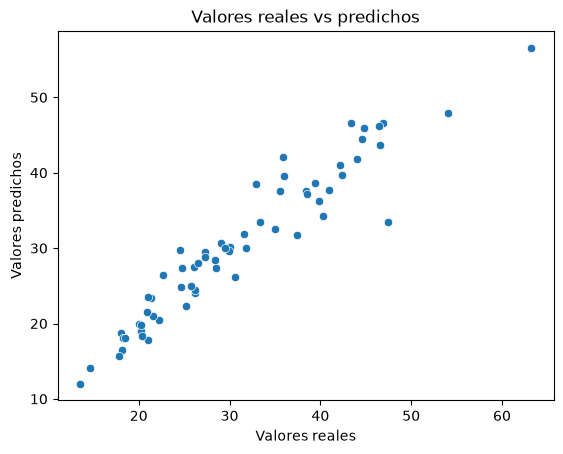

In [12]:
#Graficar los valores reales vs predichos
sns.scatterplot(x= y_test, y= y_pred)
plt.title("Valores reales vs predichos")
plt.xlabel("Valores reales")
plt.ylabel("Valores predichos")
plt.show

**Primer Analisis de Residuos**
Visualizar residuos outliers a traves del scatterplot "residuos vs predichos"

In [14]:
#Calcular reesiduos y umbral
residuos=y_test - y_pred
umbral = model.epsilon * model.scale_ #.scale_ corresponde a sigma
umbral

np.float64(1.7678605082950005)

<function matplotlib.pyplot.show(close=None, block=None)>

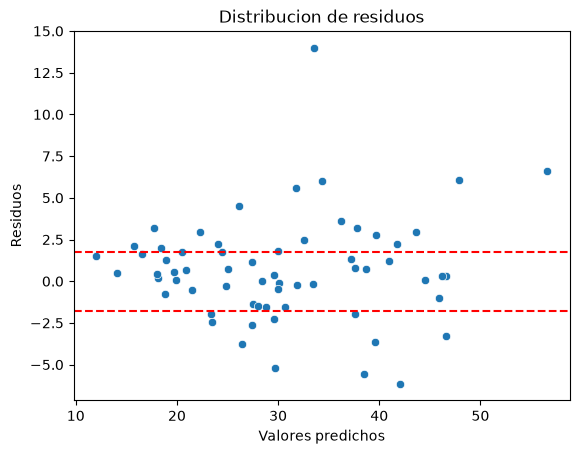

In [17]:
#Graficar distribucion de residuos
sns.scatterplot(x=y_pred, y=residuos)
plt.title("Distribucion de residuos")
plt.axhline(y=umbral, color='r', linestyle='--', label='Umbral superior')
plt.axhline(y=-umbral, color='r', linestyle='--', label='Umbral inferior')
plt.xlabel("Valores predichos")
plt.ylabel("Residuos")
plt.show

Observamos que el umbral obtenido de un epsilon por defecto, considera datos inliers como outliers, aumentar el valor de epsilon espetrando aumentar el valor del umbral.

<function matplotlib.pyplot.show(close=None, block=None)>

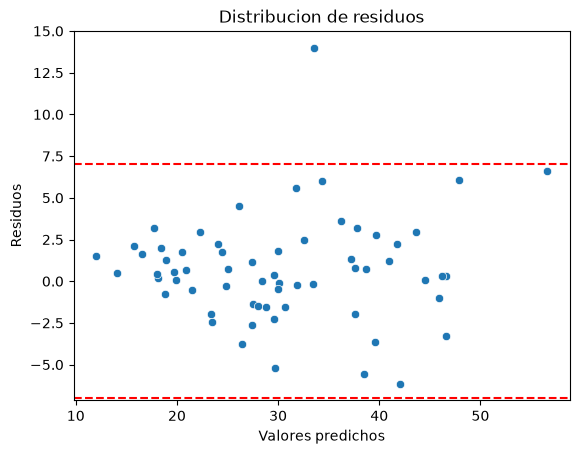

In [18]:
#Graficar nuevo valor de umbral
sns.scatterplot(x=y_pred, y=residuos)
plt.title("Distribucion de residuos")
plt.axhline(7.0, color='r', linestyle='--', label='Umbral superior')
plt.axhline(-7.0, color='r', linestyle='--', label='Umbral inferior')
plt.xlabel("Valores predichos")
plt.ylabel("Residuos")
plt.show

In [19]:
model.scale_


np.float64(1.309526302440741)

**Guardar el modelo entrenado**
Se almacena en formato .joblib(estandar del scikitlearn) para ser retomado en otro notebook para analisis residual.

In [17]:
import joblib

#Empaquetar el modelo entrenado, sus metrticas y conjuntos de datos.
artifacts={
    "model": model,
    "features": list(X.columns),
    "X_train": X_train,
    "y_train": y_train,
    "X_test": X_test,
    "y_test": y_test,
    "metrics": {
        "r2": r2,
        "mae": mae,
        "mse": mse
    }
}

#Guardar
joblib.dump(artifacts,"../../../models/exp02_ols_no_imc/multiple_regression.joblib")

['../../../models/exp02_ols_no_imc/multiple_regression.joblib']

Tarea: Resumen en libreta
 "Distribución de probabilidad Z" "Normal Estandar"